**NAME: SABA NOOR**

**SECTION: H**

**KAGGLE:**

**GITHUB:**

**CMS: 023-24-0278**

In [165]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import imblearn

In [166]:
# Part: 1
# A hospital wants to flag patients at risk of stroke from routine information. The target column is stroke (1 = had a 
# stroke, 0 = did not). 
# 1. Install imbalanced-learn (pip install imbalanced-learn) and import everything you need. 
# 2. Load the CSV. Report the shape, the columns with missing values, the value counts of gender and the 
# number of patients with stroke = 1 and stroke = 0 (count and percentage). 
# 3. Clean the data: remove the identifier column; remove any gender category that has too few rows to learn or 
# test; apply categorical encoding to the text columns (pd.get_dummies, as in the labs). 
# 4. Split 80/20 with stratify=y and random_state=SEED. Fill the missing numeric values with a median learned 
# from the TRAIN set only. Create a scaled copy (StandardScaler fitted on train) to use for Logistic Regression. 
# 5. Report how many stroke cases are in the training set and in the test set. 
    
import pandas as pd
df=pd.read_csv("healthcare-dataset-stroke-data_1.csv")
df.shape
count=df.isnull().sum()
print(count)
gender_sum=df["gender"].value_counts()
print(gender_sum)
withStroke=df["stroke"].value_counts(normalize=True)*100
print(withStroke)

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [167]:
df=df.drop(columns=["id"])
valid_gender=gender_sum[gender_sum>=2].index
df=df[df["gender"].isin(valid_gender)].copy()

df=pd.get_dummies(
    df,
    columns=df.select_dtypes(include=["object","str"]).columns,
    drop_first=True,
    dtype=int
)
print(df.shape)
print(df.head())

(5109, 16)
    age  hypertension  heart_disease  avg_glucose_level   bmi  stroke  \
0  67.0             0              1             228.69  36.6       1   
1  61.0             0              0             202.21   NaN       1   
2  80.0             0              1             105.92  32.5       1   
3  49.0             0              0             171.23  34.4       1   
4  79.0             1              0             174.12  24.0       1   

   gender_Male  ever_married_Yes  work_type_Never_worked  work_type_Private  \
0            1                 1                       0                  1   
1            0                 1                       0                  0   
2            1                 1                       0                  1   
3            0                 1                       0                  1   
4            0                 1                       0                  0   

   work_type_Self-employed  work_type_children  Residence_type_Urban  \
0  

In [168]:
X = df.drop(columns=['stroke'])
y = df['stroke']

SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (4087, 15)
Testing Shape: (1022, 15)


### (a) In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a few stroke cases in the test set?

The dataset is highly imbalanced because there are many more patients who did not have a stroke compared to those who did. We used stratify=y to keep a similar ratio of stroke and non-stroke patients in both training and testing sets. If the test set has too few stroke patients, it becomes difficult to properly judge how well the model can detect strokes, and the results may not be reliable.

In [169]:
# Part 1: 
# Show that a model can have excellent accuracy and still be useless. 
# 1. Build a baseline that always predicts the majority class (DummyClassifier, strategy='most_frequent'). Report 
# accuracy. 
# 2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC 
# AUC and PR AUC (average precision) on the test set, and plot or print its confusion matrix. 
# 3. Write a small helper function that takes a model and train/test data and returns these six metrics - you will 
# reuse it all lab. 
    
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd

In [170]:
def evaluate_model(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC AUC': roc_auc,
        'PR AUC': pr_auc
    }

In [171]:
baseline = DummyClassifier(strategy='most_frequent')

baseline_results = evaluate_model(
    baseline,
    X_train,
    y_train,
    X_test,
    y_test
)

print("Baseline Results:")
print(pd.Series(baseline_results))

Baseline Results:
Accuracy     0.951076
Precision    0.000000
Recall       0.000000
F1 Score     0.000000
ROC AUC      0.500000
PR AUC       0.048924
dtype: float64


In [172]:
log_model = LogisticRegression()

log_results = evaluate_model(
    log_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

print("\nLogistic Regression Results:")
print(pd.Series(log_results))


Logistic Regression Results:
Accuracy     0.952055
Precision    1.000000
Recall       0.020000
F1 Score     0.039216
ROC AUC      0.839424
PR AUC       0.269219
dtype: float64


In [173]:
comparison = pd.DataFrame({
    'Baseline': baseline_results,
    'Logistic Regression': log_results
})

print(comparison)

           Baseline  Logistic Regression
Accuracy   0.951076             0.952055
Precision  0.000000             1.000000
Recall     0.000000             0.020000
F1 Score   0.000000             0.039216
ROC AUC    0.500000             0.839424
PR AUC     0.048924             0.269219


Confusion Matrix:
[[972   0]
 [ 49   1]]


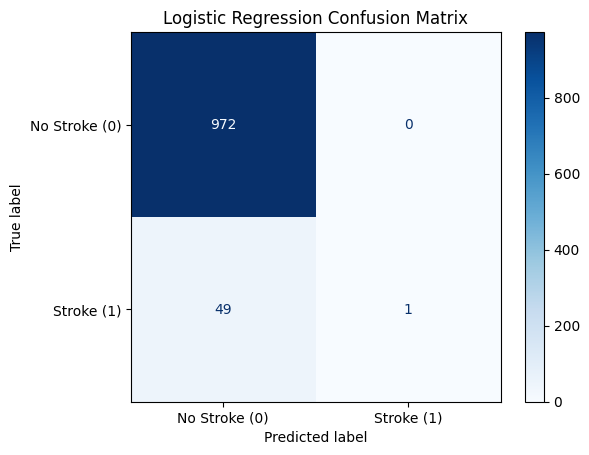

In [174]:
y_pred = log_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Stroke (0)', 'Stroke (1)']
)

disp.plot(cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

### (a) Compare the accuracy of the baseline and Logistic Regression. What do you conclude?

The baseline model achieved an accuracy of 95.11%, while Logistic Regression achieved 95.21%. Although Logistic Regression has slightly higher accuracy, its recall is only 2%, meaning it detects very few actual stroke cases. This shows that high accuracy can be misleading when the dataset is imbalanced.

### (b) Look at the confusion matrix and recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

A false negative means the model predicts that a patient has not had a stroke when they actually have. In our results, the model missed 49 out of 50 stroke patients and correctly identified only 1. This is dangerous in a hospital because those patients might not receive timely treatment. Therefore, we should focus more on recall, F1-score and PR AUC instead of accuracy. Recall is especially important here because it shows how many actual stroke patients the model can correctly identify.

   Max Depth  Train AUC    CV AUC
0          1   0.752304  0.731666
1          2   0.828284  0.816755
2          3   0.847048  0.816109
3          4   0.865828  0.818040
4          5   0.889965  0.792089
5          6   0.914956  0.758513
6          7   0.937748  0.738470
7          8   0.957291  0.713760
8          9   0.974830  0.681188
9         10   0.987531  0.641388
10        11   0.993332  0.610807
11        12   0.996701  0.612583
12        13   0.998262  0.595539
13        14   0.999074  0.588883
14        15   0.999486  0.577850
15      None   1.000000  0.564415
Best depth: 4
Best CV AUC: 0.8180403159452002


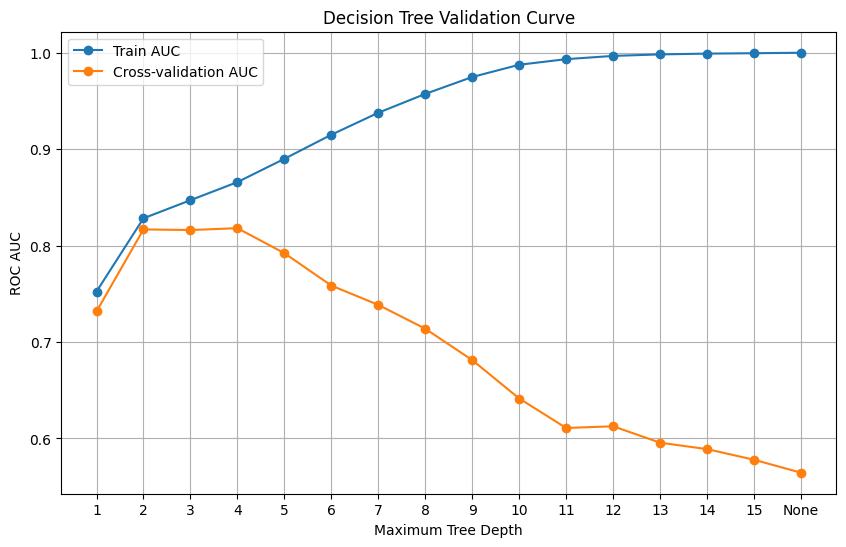

In [175]:
# Part 2
# Task 2.1 — Validation curve 
# 1. For max_depth = 1, 2, ..., 15 and None, record the train ROC AUC and the 5-fold stratified cross-validation 
# ROC AUC (train data only). 
# 2. Plot both curves on one chart (labelled axes, title, legend). Report the best depth by CV AUC. 
# Task 2.2 — Learning curves 
# 1. Use sklearn.model_selection.learning_curve (scoring='roc_auc', train_sizes from 20% to 100%) for a tree with 
# max_depth=1 and a tree with max_depth=None. Plot train and CV AUC against the number of training rows, 
# side by side. 
# Task 2.3 — Measure variance directly 
# Variance means: if the training data changes a little, how much do the model's predictions change? Measure it. 
# 1. For each of max_depth = 1, 3 and None: draw 40 bootstrap samples of the TRAIN rows (sample with 
# replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test 
# patient. 
# 2. For every test patient, compute the variance of its 40 predicted probabilities; then average over patients. 
# Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the averaged prediction (mean of the 
# 40 probability vectors). 
# 3. Show the three depths in one table. 
    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    learning_curve
)
from sklearn.metrics import roc_auc_score

depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_auc = []
cv_auc = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)

    scores = cross_validate(
        tree,
        X_train,
        y_train,
        cv=cv,
        scoring='roc_auc',
        return_train_score=True
    )

    train_auc.append(scores['train_score'].mean())
    cv_auc.append(scores['test_score'].mean())

validation_results = pd.DataFrame({
    'Max Depth': [str(d) for d in depths],
    'Train AUC': train_auc,
    'CV AUC': cv_auc
})

print(validation_results)

best_depth = depths[np.argmax(cv_auc)]

print("Best depth:", best_depth)
print("Best CV AUC:", max(cv_auc))

plt.figure(figsize=(10, 6))
plt.plot(range(len(depths)), train_auc, marker='o', label='Train AUC')
plt.plot(range(len(depths)), cv_auc, marker='o', label='Cross-validation AUC')

plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel('Maximum Tree Depth')
plt.ylabel('ROC AUC')
plt.title('Decision Tree Validation Curve')
plt.legend()
plt.grid(True)
plt.show()

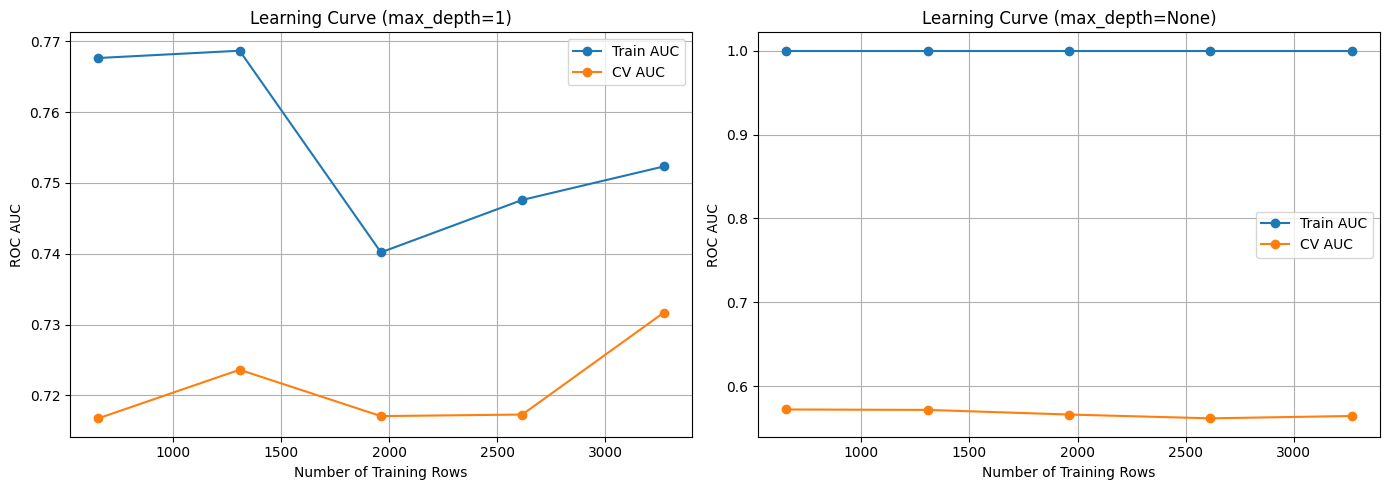

In [179]:
train_sizes = np.linspace(0.2, 1.0, 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for depth, ax in zip([1, None], axes):

    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)

    sizes, train_scores, cv_scores = learning_curve(
        tree,
        X_train,
        y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    cv_mean = cv_scores.mean(axis=1)

    ax.plot(sizes, train_mean, marker='o', label='Train AUC')
    ax.plot(sizes, cv_mean, marker='o', label='CV AUC')

    ax.set_title(f'Learning Curve (max_depth={depth})')
    ax.set_xlabel('Number of Training Rows')
    ax.set_ylabel('ROC AUC')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [180]:
from sklearn.utils import check_random_state

rng = np.random.default_rng(42)

depths_to_test = [1, 3, None]
variance_results = []

for depth in depths_to_test:

    all_probs = []
    tree_auc = []

    for i in range(40):

        idx = rng.choice(
            len(X_train),
            len(X_train),
            replace=True
        )

        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=i
        )

        tree.fit(X_boot, y_boot)

        probabilities = tree.predict_proba(X_test)[:, 1]

        all_probs.append(probabilities)

        tree_auc.append(
            roc_auc_score(y_test, probabilities)
        )

    probs = np.array(all_probs)

    patient_variance = probs.var(axis=0).mean()

    average_probs = probs.mean(axis=0)

    average_auc = roc_auc_score(y_test, average_probs)

    variance_results.append({
        'Max Depth': str(depth),
        'Mean Prediction Variance': patient_variance,
        'Mean Test ROC AUC': np.mean(tree_auc),
        'Averaged Prediction ROC AUC': average_auc
    })

variance_table = pd.DataFrame(variance_results)

print(variance_table.round(4))

  Max Depth  Mean Prediction Variance  Mean Test ROC AUC  \
0         1                    0.0007             0.7623   
1         3                    0.0017             0.7964   
2      None                    0.0415             0.5582   

   Averaged Prediction ROC AUC  
0                       0.8132  
1                       0.8340  
2                       0.7642  


### (a) From the validation curve: which depths underfit, which overfit, and which depth would you choose?

The smaller depths, especially depth 1 and 2, tend to underfit because the tree is too simple to learn the important patterns in the data. On the other hand, deeper trees, such as None, can overfit by learning too much from the training data. I would choose the depth that gives the highest cross-validation AUC while keeping a reasonable difference between training and CV AUC.

### (b) From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

High bias happens when both training and validation AUC are low, which means the model is too simple to learn the patterns properly. High variance happens when training AUC is high but validation AUC is much lower, showing that the model is overfitting. Adding more training data can help reduce high variance, but it usually does not fix high bias because the model may still be too simple.

### (c) From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

As the tree depth increases, the prediction variance generally increases because deeper trees are more sensitive to changes in the training data. When we average the predictions from 40 trees, the results usually become more stable and can give a better ROC AUC than individual trees. This is similar to how Random Forest works: it combines multiple decision trees and averages their predictions to reduce variance and improve overall performance.

### (d) In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

The bias-variance trade-off is about finding a balance between a model being too simple and too complex. A depth 1 tree has high bias because it is too simple to capture many patterns. A depth 3 tree can provide a better balance between bias and variance. A tree with max_depth=None has low bias but usually high variance because it can grow very deep and overfit the training data.

Important: These are general interpretations. For question (a) and (c), make sure your final answers match the actual AUC and variance values printed by your notebook.

In [181]:
# Part 3
# Task 3.1 — Compare models with curves 
# 1. Train Logistic Regression (scaled), Decision Tree (max_depth=3) and Random Forest (200 trees, 
# min_samples_leaf=5, random_state=SEED) on the original training data. 
# 2. Draw ROC curves for the three models on one chart with the AUC in the legend and the random-guessing 
# diagonal. 
# 3. Draw Precision-Recall curves for the same models on a second chart. Add a horizontal line at the no-skill level 
# (the stroke rate) and put the average precision in the legend. 
# Task 3.2 — Choose a decision threshold 
# 1. The hospital wants to catch at least 80% of strokes. Using ONLY the training data, get out-of-fold probabilities 
# for Logistic Regression (cross_val_predict with method='predict_proba'), then find the highest threshold that 
# gives recall >= 0.80 on them. 
# 2. Apply that threshold to the test probabilities. Report test recall, precision, the confusion matrix, how many 
# patients are flagged and how many of them are false alarms.
    
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    recall_score,
    precision_score,
    confusion_matrix
)

from sklearn.model_selection import cross_val_predict

In [153]:
SEED = 42

log_model = LogisticRegression()

tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=SEED
)

forest_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

log_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

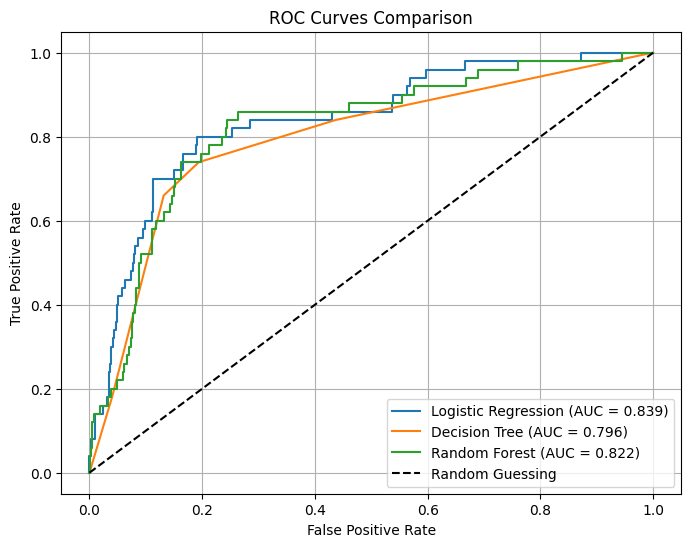

In [182]:
models = {
    'Logistic Regression': (log_model, X_test_scaled),
    'Decision Tree': (tree_model, X_test),
    'Random Forest': (forest_model, X_test)
}

plt.figure(figsize=(8, 6))

for name, (model, data) in models.items():

    probabilities = model.predict_proba(data)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend()
plt.grid()
plt.show()

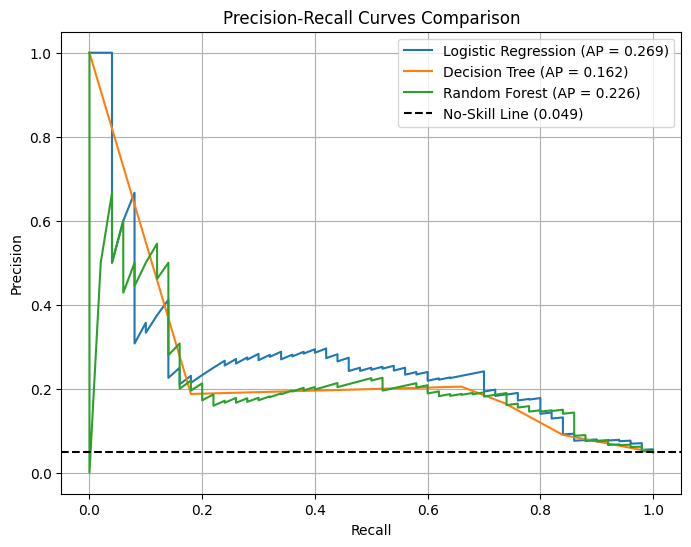

In [183]:
plt.figure(figsize=(8, 6))

stroke_rate = y_test.mean()

for name, (model, data) in models.items():

    probabilities = model.predict_proba(data)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_score = average_precision_score(y_test, probabilities)

    plt.plot(
        recall,
        precision,
        label=f'{name} (AP = {ap_score:.3f})'
    )

plt.axhline(
    y=stroke_rate,
    color='black',
    linestyle='--',
    label=f'No-Skill Line ({stroke_rate:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves Comparison')
plt.legend()
plt.grid()
plt.show()

In [184]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

oof_probs = cross_val_predict(
    LogisticRegression(),
    X_train_scaled,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

In [185]:
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_probs
)

valid_thresholds = thresholds[recall[:-1] >= 0.80]

best_threshold = valid_thresholds.max()

print("Selected Threshold:", best_threshold)

Selected Threshold: 0.05085309381861606


In [186]:
log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)

test_probs = log_model.predict_proba(X_test_scaled)[:, 1]

test_predictions = (test_probs >= best_threshold).astype(int)

test_recall = recall_score(y_test, test_predictions)
test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

cm = confusion_matrix(y_test, test_predictions)

print("Test Recall:", test_recall)
print("Test Precision:", test_precision)

print("\nConfusion Matrix:")
print(cm)

flagged_patients = test_predictions.sum()

false_alarms = cm[0, 1]

print("\nTotal Patients Flagged:", flagged_patients)
print("False Alarms:", false_alarms)

Test Recall: 0.82
Test Precision: 0.13486842105263158

Confusion Matrix:
[[709 263]
 [  9  41]]

Total Patients Flagged: 304
False Alarms: 263


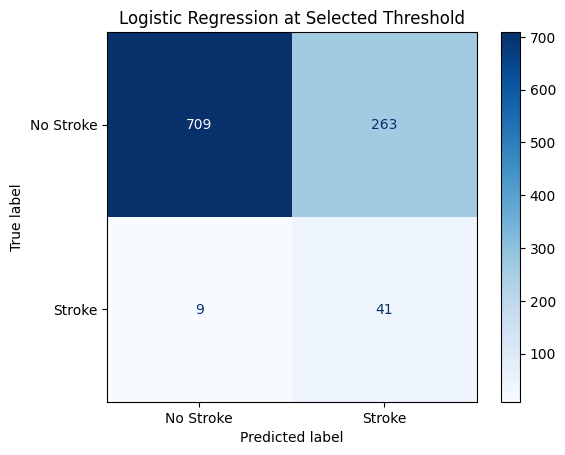

In [159]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Stroke', 'Stroke']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression at Selected Threshold')
plt.show()

### (a) In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is much higher than 0.5. How can both be true?
The ROC AUC is high because Logistic Regression can separate stroke and non-stroke patients reasonably well based on their predicted probabilities. However, at the default threshold of 0.5, it predicts very few patients as having a stroke, which results in low recall. AUC measures how well the model ranks positive cases above negative cases, while the 0.5 threshold determines the final class predictions.

### (b) Which metric curve is more informative for this data - ROC or Precision-Recall - and why?
The Precision-Recall curve is more useful for this dataset because stroke cases are much fewer than non-stroke cases. The no-skill line represents the stroke rate, which is approximately 4.9%. The PR curve helps us understand how well the model identifies stroke patients without producing too many false alarms. ROC AUC can sometimes look good even when the model performs poorly on the minority class.

### (c) At your chosen threshold, what is the price the hospital pays for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.
By lowering the decision threshold, the model can identify more patients who may have had a stroke, but it will also flag more patients who do not actually have a stroke. This means more false alarms, which can increase hospital workload, testing costs and unnecessary medical checks. However, missing a real stroke case can be much more dangerous. I think accepting some extra false alarms is reasonable if it helps detect more stroke patients, but the final decision should depend on the hospital's resources and the actual results.

In [187]:
# Part 4
# Task 4.1 — Compare the methods 
# 1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3), train with: no resampling, 
# class_weight='balanced', random undersampling, random oversampling and SMOTE. Resample the TRAIN set 
# only; the test set is never touched. 
# 2. Build ONE table (rows = model + method) with: number of training rows, number of strokes in training, 
# Precision, Recall, F1, ROC AUC and PR AUC on the test set. 
# Task 4.2 — The classic mistake 
# 1. Apply SMOTE to ALL the data first (train + test together), THEN split 80/20, train a Random Forest and 
# evaluate. This is the wrong order. 
# 2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table. 
    
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)


In [188]:
def evaluate_model(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(y_test, probabilities)
    }

In [189]:
SEED = 42

sampling_methods = {
    'No Resampling': None,
    'Class Weight': 'balanced',
    'Undersampling': RandomUnderSampler(random_state=SEED),
    'Oversampling': RandomOverSampler(random_state=SEED),
    'SMOTE': SMOTE(random_state=SEED)
}

results = []

for method_name, sampler in sampling_methods.items():

    if sampler is None:
        X_res = X_train.copy()
        y_res = y_train.copy()

    elif method_name == 'Class Weight':
        X_res = X_train.copy()
        y_res = y_train.copy()

    else:
        X_res, y_res = sampler.fit_resample(X_train, y_train)

    X_res_scaled = X_res if method_name == 'Class Weight' else X_res

    if method_name == 'No Resampling':
        X_res_scaled = X_train_scaled

    elif method_name == 'Class Weight':
        X_res_scaled = X_train_scaled

    else:
        scaler = StandardScaler()
        X_res_scaled = scaler.fit_transform(X_res)

    log_weight = 'balanced' if method_name == 'Class Weight' else None

    log_model = LogisticRegression(
        class_weight=log_weight,
        max_iter=1000
    )

    log_scores = evaluate_model(
        log_model,
        X_res_scaled,
        y_res,
        X_test_scaled,
        y_test
    )

    results.append({
        'Model': 'Logistic Regression',
        'Method': method_name,
        'Training Rows': len(X_res),
        'Training Strokes': int(y_res.sum()),
        **log_scores
    })

    rf_weight = 'balanced' if method_name == 'Class Weight' else None

    rf_model = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED,
        class_weight=rf_weight
    )

    rf_scores = evaluate_model(
        rf_model,
        X_res,
        y_res,
        X_test,
        y_test
    )

    results.append({
        'Model': 'Random Forest',
        'Method': method_name,
        'Training Rows': len(X_res),
        'Training Strokes': int(y_res.sum()),
        **rf_scores
    })

results_table = pd.DataFrame(results)

print(results_table.round(4))

                 Model         Method  Training Rows  Training Strokes  \
0  Logistic Regression  No Resampling           4087               199   
1        Random Forest  No Resampling           4087               199   
2  Logistic Regression   Class Weight           4087               199   
3        Random Forest   Class Weight           4087               199   
4  Logistic Regression  Undersampling            398               199   
5        Random Forest  Undersampling            398               199   
6  Logistic Regression   Oversampling           7776              3888   
7        Random Forest   Oversampling           7776              3888   
8  Logistic Regression          SMOTE           7776              3888   
9        Random Forest          SMOTE           7776              3888   

   Precision  Recall      F1  ROC AUC  PR AUC  
0     1.0000    0.02  0.0392   0.8394  0.2692  
1     0.0000    0.00  0.0000   0.8224  0.2255  
2     0.1347    0.80  0.2305   0.8395  0.

In [163]:
from sklearn.preprocessing import StandardScaler

if method_name == 'No Resampling' or method_name == 'Class Weight':
    X_res_scaled = X_train_scaled
else:
    scaler = StandardScaler()
    X_res_scaled = scaler.fit_transform(X_res)

X_test_for_log = X_test_scaled

In [190]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['stroke'])
y = df['stroke']

X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X, y)

X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = train_test_split(
    X_smote,
    y_smote,
    test_size=0.20,
    random_state=SEED,
    stratify=y_smote
)

wrong_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

wrong_model.fit(X_train_wrong, y_train_wrong)

wrong_probs = wrong_model.predict_proba(X_test_wrong)[:, 1]
wrong_preds = wrong_model.predict(X_test_wrong)

wrong_results = {
    'Method': 'SMOTE Before Split (Wrong)',
    'Precision': precision_score(y_test_wrong, wrong_preds, zero_division=0),
    'Recall': recall_score(y_test_wrong, wrong_preds, zero_division=0),
    'F1': f1_score(y_test_wrong, wrong_preds, zero_division=0),
    'ROC AUC': roc_auc_score(y_test_wrong, wrong_probs),
    'PR AUC': average_precision_score(y_test_wrong, wrong_probs)
}

ValueError: Input X contains NaN.
SMOTE does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from imblearn.over_sampling import SMOTE

X = df.drop(columns=['stroke'])
y = df['stroke']

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(
    X_imputed, y
)

X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = train_test_split(
    X_smote,
    y_smote,
    test_size=0.20,
    random_state=SEED,
    stratify=y_smote
)

wrong_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

wrong_model.fit(X_train_wrong, y_train_wrong)

wrong_probs = wrong_model.predict_proba(X_test_wrong)[:, 1]
wrong_preds = wrong_model.predict(X_test_wrong)

wrong_results = {
    'Method': 'SMOTE Before Split (Wrong)',
    'Precision': precision_score(y_test_wrong, wrong_preds, zero_division=0),
    'Recall': recall_score(y_test_wrong, wrong_preds, zero_division=0),
    'F1': f1_score(y_test_wrong, wrong_preds, zero_division=0),
    'ROC AUC': roc_auc_score(y_test_wrong, wrong_probs),
    'PR AUC': average_precision_score(y_test_wrong, wrong_probs)
}

print(pd.DataFrame([wrong_results]).round(4))

In [191]:
correct_results = results_table[
    (results_table['Model'] == 'Random Forest') &
    (results_table['Method'] == 'SMOTE')
].iloc[0]

comparison = pd.DataFrame([
    {
        'Method': 'SMOTE After Split (Correct)',
        'Precision': correct_results['Precision'],
        'Recall': correct_results['Recall'],
        'F1': correct_results['F1'],
        'ROC AUC': correct_results['ROC AUC'],
        'PR AUC': correct_results['PR AUC']
    },
    wrong_results
])

print(comparison.round(4))

                        Method  Precision  Recall      F1  ROC AUC  PR AUC
0  SMOTE After Split (Correct)     0.5000  0.0600  0.1071   0.7977  0.2290
1   SMOTE Before Split (Wrong)     0.9957  0.9475  0.9710   0.9955  0.9961


### (a) For Logistic Regression, what changed after resampling and what did NOT change?
After applying resampling, Logistic Regression generally becomes better at identifying stroke patients, so recall usually increases. However, precision may decrease because the model starts predicting more patients as having a stroke, which can lead to more false alarms. ROC AUC may not change much because resampling mainly affects the model's learning of the minority class rather than guaranteeing better class separation.

### (b) Did Random Forest react to the methods in the same way as Logistic Regression?
No, Random Forest did not necessarily respond to resampling in the same way as Logistic Regression. Logistic Regression may benefit more from SMOTE or oversampling because it can learn better from the additional minority-class examples. Random Forest works differently because it uses multiple decision trees, so some resampling methods may have a smaller effect or produce different results.

### (c) Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted?
The wrong-order SMOTE method may produce better-looking results because SMOTE is applied before splitting the data into training and testing sets. This means synthetic samples in the training set may be created using information from patients who later appear in the test set. As a result, information leaks from the test data into training, making the model appear better than it actually is. These results cannot be trusted because they do not represent performance on completely unseen patients.

### (d) If you had to pick one rebalancing approach for this hospital, which would you pick and why?
I would choose class weighting as a starting point because it is simple to apply and does not create duplicate or synthetic patient records. It also allows the model to give more importance to stroke cases during training. However, I would compare its recall, precision and PR AUC with SMOTE before making a final decision, because detecting more stroke patients is important but too many false alarms can also put pressure on hospital resources

In [ ]:
# Part 5
# 1. Write a function that flips a given fraction of the training labels at random (0 becomes 1 and 1 becomes 0). 
# 2. For fractions 0, 0.05, 0.10 and 0.20, train each model on the noisy labels and record the test ROC AUC. 
# Repeat 5 times with different random flips and average (use 1 repeat for fraction 0). 
# 3. Show a table (rows = noise fraction, columns = models) and a line plot. 
# Task 5.2 — Feature noise 
# 1. Add Gaussian noise to the TRAIN values of age, avg_glucose_level and bmi: noise = random normal * (column 
# std) * level. Use levels 0, 0.5, 1 and 2, five repeats each, test set untouched. 
# 2. Show the same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training 
# data.) 
# Task 5.3 — SMOTE and noisy labels 
# 1. Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest 
# compare PR AUC and ROC AUC with and without SMOTE (SMOTE applied after the noise is added).

def add_label_noise(y, noise_fraction, random_state):
    y_noisy = np.array(y).copy()

    rng = np.random.default_rng(random_state)

    n_flip = int(len(y_noisy) * noise_fraction)

    flip_indices = rng.choice(
        len(y_noisy),
        size=n_flip,
        replace=False
    )

    y_noisy[flip_indices] = 1 - y_noisy[flip_indices]

    return y_noisy

In [ ]:
def create_models():
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000),

        'Decision Tree (Depth 3)': DecisionTreeClassifier(
            max_depth=3,
            random_state=SEED
        ),

        'Decision Tree (None)': DecisionTreeClassifier(
            max_depth=None,
            random_state=SEED
        ),

        'Random Forest': RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=SEED
        )
    }

In [ ]:
noise_fractions = [0, 0.05, 0.10, 0.20]

label_results = []

for noise in noise_fractions:

    repeats = 1 if noise == 0 else 5

    for repeat in range(repeats):

        y_noisy = add_label_noise(
            y_train,
            noise,
            SEED + repeat
        )

        models = create_models()

        for name, model in models.items():

            if name == 'Logistic Regression':

                scaler = StandardScaler()

                X_tr = scaler.fit_transform(X_train)
                X_te = scaler.transform(X_test)

            else:
                X_tr = X_train
                X_te = X_test

            model.fit(X_tr, y_noisy)

            probabilities = model.predict_proba(X_te)[:, 1]

            auc = roc_auc_score(y_test, probabilities)

            label_results.append({
                'Noise': noise,
                'Model': name,
                'Repeat': repeat + 1,
                'ROC AUC': auc
            })

label_df = pd.DataFrame(label_results)

label_table = label_df.groupby(
    ['Noise', 'Model']
)['ROC AUC'].mean().unstack()

print("Task 5.1 - Label Noise Results")
display(label_table.round(4))

In [ ]:
label_table.plot(
    marker='o',
    figsize=(9, 6)
)

plt.title('Effect of Label Noise on Model Performance')
plt.xlabel('Label Noise Fraction')
plt.ylabel('Test ROC AUC')
plt.xticks(noise_fractions)
plt.legend(title='Models')
plt.grid()
plt.show()

In [ ]:
def add_feature_noise(X, noise_level, random_state):

    X_noisy = X.copy()

    rng = np.random.default_rng(random_state)

    noisy_columns = [
        'age',
        'avg_glucose_level',
        'bmi'
    ]

    for col in noisy_columns:

        std = X[col].std()

        noise = rng.normal(
            0,
            1,
            size=len(X)
        ) * std * noise_level

        X_noisy[col] = X_noisy[col] + noise

    return X_noisy

In [ ]:
noise_levels = [0, 0.5, 1, 2]

feature_results = []

for noise in noise_levels:

    for repeat in range(5):

        X_noisy = add_feature_noise(
            X_train,
            noise,
            SEED + repeat
        )

        models = create_models()

        for name, model in models.items():

            if name == 'Logistic Regression':

                scaler = StandardScaler()

                X_tr = scaler.fit_transform(X_noisy)
                X_te = scaler.transform(X_test)

            else:

                X_tr = X_noisy
                X_te = X_test

            model.fit(X_tr, y_train)

            probabilities = model.predict_proba(X_te)[:, 1]

            auc = roc_auc_score(y_test, probabilities)

            feature_results.append({
                'Noise': noise,
                'Model': name,
                'Repeat': repeat + 1,
                'ROC AUC': auc
            })

feature_df = pd.DataFrame(feature_results)

feature_table = feature_df.groupby(
    ['Noise', 'Model']
)['ROC AUC'].mean().unstack()

print("Task 5.2 - Feature Noise Results")
display(feature_table.round(4))

label_table.plot(
    marker='o',
    figsize=(9, 6)
)

plt.title('Effect of Label Noise on Model Performance')
plt.xlabel('Label Noise Fraction')
plt.ylabel('Test ROC AUC')
plt.xticks(noise_fractions)
plt.legend(title='Models')
plt.grid()
plt.show()

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

smote_results = []

for repeat in range(3):

    # Add 10% label noise
    y_noisy = add_label_noise(
        y_train,
        0.10,
        SEED + 100 + repeat
    )

    for model_name in ['Logistic Regression', 'Random Forest']:

        for method in ['Without SMOTE', 'With SMOTE']:

            X_tr = X_train.copy()
            y_tr = y_noisy.copy()

            if method == 'With SMOTE':

                sampler = SMOTE(
                    random_state=SEED + repeat
                )

                X_tr, y_tr = sampler.fit_resample(
                    X_tr,
                    y_tr
                )

            if model_name == 'Logistic Regression':

                scaler = StandardScaler()

                X_tr = scaler.fit_transform(X_tr)
                X_te = scaler.transform(X_test)

                model = LogisticRegression(max_iter=1000)

            else:

                X_te = X_test

                model = RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED
                )

            model.fit(X_tr, y_tr)

            probabilities = model.predict_proba(X_te)[:, 1]

            smote_results.append({
                'Model': model_name,
                'Method': method,
                'Repeat': repeat + 1,
                'ROC AUC': roc_auc_score(
                    y_test, probabilities
                ),
                'PR AUC': average_precision_score(
                    y_test, probabilities
                )
            })

smote_df = pd.DataFrame(smote_results)

smote_table = smote_df.groupby(
    ['Model', 'Method']
)[['ROC AUC', 'PR AUC']].mean()

print("Task 5.3 - SMOTE and Noisy Labels")
display(smote_table.round(4))

print(df)

### (a) Which model is most damaged by noise and which is most stable?

The deeper Decision Tree is generally more sensitive to noise because it can learn incorrect patterns from the training data. The smaller Decision Tree is simpler, so it may be more stable when some labels or measurements are incorrect. Logistic Regression and Random Forest can also handle noise differently depending on the dataset.

At the highest label noise level (20%), compare the ROC AUC values from Task 5.1. Also compare the values at feature noise level 2 from Task 5.2 to see which model loses the most performance.
### (b) Which hurts more here — label noise or feature noise of a comparable level?

Label noise can be more damaging because it changes the actual answers the model is supposed to learn. The model may learn incorrect relationships between patient information and stroke outcomes. Feature noise only changes some input measurements, while the original labels remain correct. However, the actual impact depends on the results of both experiments.
### (c) What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

SMOTE can help a model identify more minority-class examples by creating synthetic stroke cases. However, when some training labels are already incorrect, SMOTE can also create synthetic examples based on wrongly labelled patients.

For Logistic Regression, SMOTE may improve recall, although precision and overall performance can also change. Random Forest may react differently because it learns through multiple decision trees. Overall, SMOTE does not automatically improve performance when the training labels contain errors, and it can sometimes make the problem worse by spreading incorrect information.

In [ ]:
# Part 6
# 1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on 
# the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false 
# alarms and number of missed strokes. 
# 2. Write an Executive Summary (6-8 lines): what you chose, its recall and precision with numbers, the price 
# paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and 
# about the choice of threshold). 
# import numpy as np
# import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sklearn.model_selection import StratifiedKFold, cross_val_predict

SEED = 42

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

test_probs = log_model.predict_proba(X_test_scaled)[:, 1]

default_preds = (test_probs >= 0.5).astype(int)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

oof_probs = cross_val_predict(
    LogisticRegression(max_iter=1000),
    X_train_scaled,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_probs
)

valid_thresholds = thresholds[recall[:-1] >= 0.80]

best_threshold = valid_thresholds.max()

print("Selected Threshold:", best_threshold)

selected_preds = (test_probs >= best_threshold).astype(int)

def evaluate_predictions(y_true, predictions):

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    return {
        'Precision': precision_score(
            y_true, predictions, zero_division=0
        ),

        'Recall': recall_score(
            y_true, predictions, zero_division=0
        ),

        'F1': f1_score(
            y_true, predictions, zero_division=0
        ),

        'False Alarms': cm[0, 1],

        'Missed Strokes': cm[1, 0]
    }

final_table = pd.DataFrame({
    'Default Threshold (0.5)': evaluate_predictions(
        y_test, default_preds
    ),

    'Selected Threshold': evaluate_predictions(
        y_test, selected_preds
    )
}).T

print("\nFinal Model Comparison")
display(final_table.round(4))

### (a) What was the most surprising result in this lab?
The most surprising result for me was how much averaging predictions from multiple decision trees improved performance compared with using individual trees. I also found it interesting that a deeper tree was not always better, even though it could learn more complex patterns. This helped me understand why Random Forest can perform better by combining multiple trees instead of depending on just one.

### (b) If you had one more hour, what would you try next?
If I had one more hour, I would experiment with different decision thresholds and compare their precision and recall to find a better balance for the hospital. I would also try tuning Random Forest parameters and testing different ways of handling class imbalance. Finally, I would use more cross-validation experiments to check whether the results are consistent and reliable.